# Задание 4.3

Предположим, что «симметричную» монету бросают до первого появления герба. Найдите вероятность события $A$, состоящего в том, что будет произведено не более пяти бросаний.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Вероятностная модель.** Обозначим Г — герб, Р — решка. Опыт заканчивается на первом гербе, поэтому

$$
\Omega=\{\omega_1,\omega_2,\omega_3,\dots\},\qquad \omega_k=\underbrace{\text{Р}\,\text{Р}\dots\text{Р}}_{k-1}\,\text{Г}.
$$

Броски независимы и $\mathbb P(\text{Г})=\mathbb P(\text{Р})=\frac12$, поэтому

$$
\mathbb P(\omega_k)=\Big(\frac12\Big)^{k-1}\cdot\frac12=\frac{1}{2^k},\qquad \sum_{k=1}^{\infty}\frac{1}{2^k}=1 .
$$

Число бросаний $\tau$ имеет **геометрическое распределение**: $\mathbb P(\tau=k)=q^{k-1}p$, $p=q=\frac12$.

**Событие $A=\{\tau\le5\}=\{\omega_1,\dots,\omega_5\}$:**

$$
\mathbb P(A)=\sum_{k=1}^{5}\frac{1}{2^k}=1-\frac{1}{2^5}=\frac{31}{32}=0{,}96875 .
$$

То же через противоположное событие: $\bar A$ — первые 5 бросков дали решку, $\mathbb P(\bar A)=\left(\frac12\right)^5$.

**Статистическая проверка:** моделируем последовательности бросков, для каждой находим номер первого герба $\tau$ и строим $\hat p(A)=N(A)/N$.

P(A) = sum_(k=1..5) 1/2^k = 31/32 = 0.96875


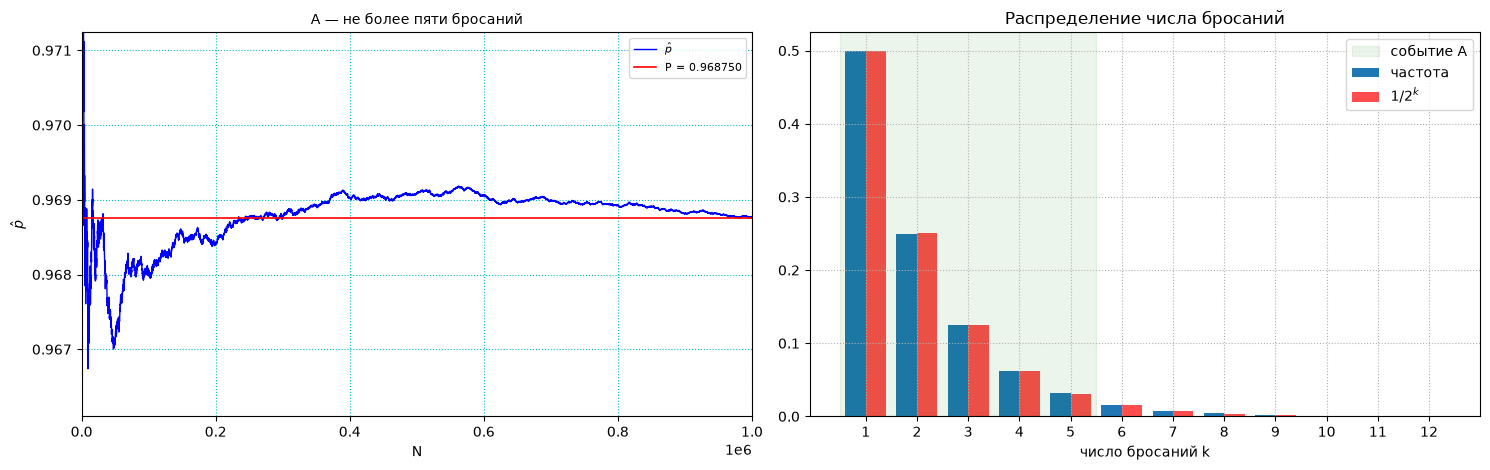

p̂(A) = 0.968756 при N = 1000000;  |p̂ - P| = 6.00e-06


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точная вероятность ----------
P_A = sum(Fraction(1, 2**k) for k in range(1, 6))
print(f"P(A) = sum_(k=1..5) 1/2^k = {P_A} = {float(P_A)}")

# ---------- Моделирование ----------
N, K = 1_000_000, 64                          # K бросков хватает: P(нет герба за 64 броска) = 2^-64
tosses = rng.random((N, K)) < 0.5             # True — выпал герб
tau = tosses.argmax(axis=1) + 1               # номер первого герба = число бросаний
hits = tau <= 5                               # событие A

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
pA = plot_freq(axes[0], hits, float(P_A), "A — не более пяти бросаний")

# распределение числа бросаний: частоты против 1/2^k
k = np.arange(1, 13)
emp = np.array([(tau == j).mean() for j in k])
axes[1].bar(k - 0.2, emp, width=0.4, label="частота")
axes[1].bar(k + 0.2, 0.5**k, width=0.4, color="red", alpha=0.7, label=r"$1/2^k$")
axes[1].axvspan(0.5, 5.5, color="green", alpha=0.08, label="событие A")
axes[1].set_xticks(k); axes[1].set_xlabel("число бросаний k"); axes[1].set_title("Распределение числа бросаний")
axes[1].grid(ls=":"); axes[1].legend()
fig.tight_layout()
plt.show()

print(f"p̂(A) = {pA:.6f} при N = {N};  |p̂ - P| = {abs(pA - float(P_A)):.2e}")